# v3 평가 분석 (3팀)

학습 노트북에서 자동 출력되는 메인 비교표(Top-1/Top-3/Det rate) 위에 추가되는 분석.

**입력**:
- v2 결과 JSON (e14, 합성 v2 강화 학습 모델): `eval/rtmdet_tiny_synth_e14_seed100_results.json`
- v3 결과 JSON (e11, 합성 v3 강화 학습 모델): `eval/rtmdet_tiny_synth_e11_seed100_results.json`
- baseline 결과 JSON (e15, 합성 통합본 v2 이전 실패 모델): `eval/rtmdet_tiny_synth_e15_seed100_results.json` (참고용)

**분석 항목**:
1. 환경별 정답률 (palm/dark 가설 검증)
2. pin-class 예측 분포 (hallucination 변화)
3. 단일 알약 정확도
4. count별 정답률
5. 페어 1/2/3 라벨 이동 (백본 한계 검증)
6. Plan A/B 분기 판정

## 1. 환경 셋업 + 재사용 함수

학습 노트북 셀 34, 40에서 `nfc` / `iou_xyxy` / `evaluate_v4_json` 그대로 재활용. 서브셋 분석용 `filter_results` 추가.

In [13]:
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# ────── 경로 ──────
V2_RESULT = Path(r'D:\pill_detection\eval\rtmdet_tiny_synth_e14_seed100_results.json')
V3_RESULT = Path(r'D:\pill_detection\eval\rtmdet_tiny_synth_e11_seed100_results.json')
BASELINE_RESULT = Path(r'D:\pill_detection\eval\rtmdet_tiny_synth_e15_seed100_results.json')  # 참고용
FIG_DIR   = Path(r'D:\pill_detection\analysis\figures_v3_eval')
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'V2 (e14) 존재:       {V2_RESULT.exists()}')
print(f'V3 (e11) 존재:       {V3_RESULT.exists()}')
print(f'baseline (e15) 존재: {BASELINE_RESULT.exists()}  (참고용)')
print(f'FIG_DIR: {FIG_DIR}')


# ────── 학습 노트북 셀 34, 40에서 그대로 가져온 함수 ──────
def nfc(s):
    return unicodedata.normalize('NFC', s) if isinstance(s, str) else s


def iou_xyxy(b1, b2):
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    return inter / (a1 + a2 - inter + 1e-9)


def evaluate_v4_json(output_json, iou_thr=0.5):
    """v4 형식 결과 JSON 채점 (학습 노트북 셀 40 동일)."""
    n_top1 = n_top3 = n_match = 0
    img_top1_full = img_top3_full = 0
    n_false_pos = 0
    total_gt = sum(len(r['gt_bboxes']) for r in output_json['results'])
    n_imgs = len(output_json['results'])

    if total_gt == 0:
        return None

    for r in output_json['results']:
        gts = r['gt_bboxes']
        preds = r['predictions']
        used = set()
        img_all_top1 = bool(gts)
        img_all_top3 = bool(gts)

        for gt in gts:
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(preds):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j

            if best_iou >= iou_thr and best_idx >= 0:
                n_match += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in preds[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    n_top1 += 1
                else:
                    img_all_top1 = False
                if gt_name in top3:
                    n_top3 += 1
                else:
                    img_all_top3 = False
            else:
                img_all_top1 = False
                img_all_top3 = False

        if img_all_top1:
            img_top1_full += 1
        if img_all_top3:
            img_top3_full += 1
        n_false_pos += len(preds) - len(used)

    return {
        'detection_rate': n_match / total_gt,
        'top1_accuracy':  n_top1  / total_gt,
        'top3_accuracy':  n_top3  / total_gt,
        'image_top1':     img_top1_full / n_imgs,
        'image_top3':     img_top3_full / n_imgs,
        'n_top1': n_top1, 'n_top3': n_top3, 'n_match': n_match,
        'n_false_pos': n_false_pos, 'total_gt': total_gt, 'n_imgs': n_imgs,
    }


def filter_results(data, filename_set):
    """주어진 filename 집합에 속하는 results만 반환 (서브셋 분석용)."""
    return {**data, 'results': [r for r in data['results'] if r['filename'] in filename_set]}


print('함수 정의 완료: nfc / iou_xyxy / evaluate_v4_json / filter_results')

V2 (e14) 존재:       True
V3 (e11) 존재:       True
baseline (e15) 존재: True  (참고용)
FIG_DIR: D:\pill_detection\analysis\figures_v3_eval
함수 정의 완료: nfc / iou_xyxy / evaluate_v4_json / filter_results


## 2. 데이터 로드 + 33장 메타정보

v2(e14) / v3(e11) 결과 JSON 로드. 33장 환경/count/페어 라벨링은 진단 노트북 셀 19에서 가져옴.

세션 44 기록값과 v2 자체검증으로 무결성 확인.

In [14]:
# v2 / v3 결과 JSON 로드
with open(V2_RESULT, encoding='utf-8') as f:
    v2_data = json.load(f)
with open(V3_RESULT, encoding='utf-8') as f:
    v3_data = json.load(f)

print(f"v2: best_epoch={v2_data['best_epoch']}, num_images={v2_data['num_images']}, num_gt={v2_data['num_gt_bboxes']}")
print(f"v3: best_epoch={v3_data['best_epoch']}, num_images={v3_data['num_images']}, num_gt={v3_data['num_gt_bboxes']}")

# 자체검증: 세션 44 기록값과 v2 일치 여부
v2_metrics = evaluate_v4_json(v2_data)
print(f"\n=== v2 자체검증 (세션 44 기록 일치 여부) ===")
print(f"Top-1: {v2_metrics['top1_accuracy']:.1%} (세션 44 기록 31.9%)")
print(f"Top-3: {v2_metrics['top3_accuracy']:.1%} (세션 44 기록 53.2%)")
print(f"Det:   {v2_metrics['detection_rate']:.1%} (세션 44 기록 95.7%)")
print(f"FP:    {v2_metrics['n_false_pos']} (세션 44 기록 100)")

# v3 출력
v3_metrics = evaluate_v4_json(v3_data)
print(f"\n=== v3 측정값 ===")
print(f"Top-1: {v3_metrics['top1_accuracy']:.1%}")
print(f"Top-3: {v3_metrics['top3_accuracy']:.1%}")
print(f"Det:   {v3_metrics['detection_rate']:.1%}")
print(f"FP:    {v3_metrics['n_false_pos']}")

# filename 일치 검증
v2_files = {r['filename'] for r in v2_data['results']}
v3_files = {r['filename'] for r in v3_data['results']}
assert v2_files == v3_files, f"파일 불일치: v2-v3={v2_files-v3_files}, v3-v2={v3_files-v2_files}"
print(f"\n파일 일치: {len(v2_files)}장 동일")

# 33장 파일명 출력 (참고용)
all_files = sorted(v2_files)
print(f"\n=== 33장 파일명 ===")
for i, f in enumerate(all_files):
    print(f"  [{i:2d}] {f}")

v2: best_epoch=14, num_images=33, num_gt=47
v3: best_epoch=11, num_images=33, num_gt=47

=== v2 자체검증 (세션 44 기록 일치 여부) ===
Top-1: 31.9% (세션 44 기록 31.9%)
Top-3: 53.2% (세션 44 기록 53.2%)
Det:   95.7% (세션 44 기록 95.7%)
FP:    100 (세션 44 기록 100)

=== v3 측정값 ===
Top-1: 29.8%
Top-3: 55.3%
Det:   93.6%
FP:    99

파일 일치: 33장 동일

=== 33장 파일명 ===
  [ 0] 게보린정 300mg_3.png
  [ 1] 글리아타민연질캡슐.png
  [ 2] 낙소졸정 500_20mg.png
  [ 3] 넥시움정 40mg.png
  [ 4] 노바스크정 5mg.png
  [ 5] 놀텍정 10mg.png
  [ 6] 디카테오정.png
  [ 7] 라시도필캡슐(비매품).png
  [ 8] 마이칼디정.png
  [ 9] 맥시부펜이알정.png
  [10] 뮤테란캡슐 100mg.png
  [11] 비모보정 500_20mg.png
  [12] 비오플250캡슐.png
  [13] 비타비백정(비타민).png
  [14] 아보다트연질캡슐 0.5mg_1.png
  [15] 아스피린프로텍트정100mg.png
  [16] 아토르바정 10mg.png
  [17] 엔테론정 150mg.png
  [18] 울트라셋이알서방정.png
  [19] 인사돌플러스정 35mg_.png
  [20] 인사돌플러스정.png
  [21] 자누비아정 50mg.png
  [22] 자트랄엑스엘정 10mg.png
  [23] 졸로푸트정 100mg.png
  [24] 종근당글리아티린연질캡슐.png
  [25] 지르텍정(세티리진염산염).png
  [26] 지르텍정.png
  [27] 케이캡정 50mg.png
  [28] 쿠에타핀정 25mg.png
  [29] 타이레놀500mg.png
  [30]

## 3. 33장 환경 라벨 (진단 노트북 셀 19)

baseline → v2 비교 분석 시 사용된 env_labels dict 그대로. 이미지 단위 환경 라벨이지만, 한 이미지의 모든 GT가 같은 환경이므로 47 GT 박스 단위로 펼쳐서 분석.

기록 분포 (n_GT 단위):
- paper 7 / bottle 2 / cloth 10 / palm 20 / desk 5 / dark 2 / box 1 = 47

In [15]:
# 진단 노트북 셀 19 환경 라벨 그대로
env_labels = {
    '게보린정 300mg_3.png': 'paper',
    '글리아타민연질캡슐.png': 'palm',
    '낙소졸정 500_20mg.png': 'palm',
    '넥시움정 40mg.png': 'cloth',
    '노바스크정 5mg.png': 'cloth',
    '놀텍정 10mg.png': 'palm',
    '디카테오정.png': 'palm',
    '라시도필캡슐(비매품).png': 'palm',
    '마이칼디정.png': 'paper',
    '맥시부펜이알정.png': 'paper',
    '뮤테란캡슐 100mg.png': 'bottle',
    '비모보정 500_20mg.png': 'palm',
    '비오플250캡슐.png': 'palm',
    '비타비백정(비타민).png': 'palm',
    '아보다트연질캡슐 0.5mg_1.png': 'palm',
    '아스피린프로텍트정100mg.png': 'palm',
    '아토르바정 10mg.png': 'cloth',
    '엔테론정 150mg.png': 'cloth',
    '울트라셋이알서방정.png': 'box',
    '인사돌플러스정 35mg_.png': 'palm',
    '인사돌플러스정.png': 'palm',
    '자누비아정 50mg.png': 'cloth',
    '자트랄엑스엘정 10mg.png': 'cloth',
    '졸로푸트정 100mg.png': 'paper',
    '종근당글리아티린연질캡슐.png': 'dark',
    '지르텍정(세티리진염산염).png': 'palm',
    '지르텍정.png': 'desk',
    '케이캡정 50mg.png': 'desk',
    '쿠에타핀정 25mg.png': 'desk',
    '타이레놀500mg.png': 'palm',
    '타이레놀이알서방정(아세트아미노펜)(수출용).png': 'palm',
    '트루비타정 60mg.png': 'bottle',
    '프로스카정.png': 'desk',
}

# 라벨 매칭 검증
missing = v2_files - set(env_labels.keys())
extra = set(env_labels.keys()) - v2_files
assert not missing and not extra, f"missing={missing}, extra={extra}"
print(f"라벨 매칭 OK: {len(env_labels)} 파일")

# 이미지 단위 → GT 박스 단위 환경 분포 검증
env_gt_count = {}
for r in v2_data['results']:
    env = env_labels[r['filename']]
    env_gt_count[env] = env_gt_count.get(env, 0) + len(r['gt_bboxes'])

print(f"\n=== GT 박스 단위 환경 분포 ===")
for env in ['paper', 'bottle', 'cloth', 'palm', 'desk', 'dark', 'box']:
    n = env_gt_count.get(env, 0)
    print(f"  {env:8s}: {n}개")
print(f"  합계      : {sum(env_gt_count.values())}개 (기록: 47)")

라벨 매칭 OK: 33 파일

=== GT 박스 단위 환경 분포 ===
  paper   : 7개
  bottle  : 2개
  cloth   : 10개
  palm    : 20개
  desk    : 5개
  dark    : 2개
  box     : 1개
  합계      : 47개 (기록: 47)


## 4. 환경별 정답률 (v2 vs v3)

핵심 가설 검증:
- **palm** (n=20, 가장 큰 환경): 30% → 35%+ (palm 풀 7배 + 마스크 + 침식 효과)
- **dark** (n=2): 0% → 10~20% (HSV value_delta 60 효과)

처방이 의도한 효과를 냈는지 환경별로 확인. n 작은 환경(box=1, dark=2, bottle=2)은 통계 의미 약함 — 케이스 명단까지 봐야 함.

In [16]:
def env_breakdown(data, env_labels, iou_thr=0.5):
    """환경별 Top-1, Top-3, Detection rate 계산 (GT 박스 단위)."""
    env_stats = {}

    for r in data['results']:
        env = env_labels[r['filename']]
        if env not in env_stats:
            env_stats[env] = {'n_gt': 0, 'n_top1': 0, 'n_top3': 0, 'n_match': 0, 'cases': []}

        gts = r['gt_bboxes']
        preds = r['predictions']
        used = set()

        for gt_idx, gt in enumerate(gts):
            env_stats[env]['n_gt'] += 1
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(preds):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j

            verdict = 'det_fail'
            top1_pred = None
            if best_iou >= iou_thr and best_idx >= 0:
                env_stats[env]['n_match'] += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in preds[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                top1_pred = top3[0] if top3 else None
                if top3 and top3[0] == gt_name:
                    env_stats[env]['n_top1'] += 1
                    verdict = 'top1'
                elif gt_name in top3:
                    env_stats[env]['n_top3'] += 1
                    verdict = 'top3'
                else:
                    verdict = 'wrong'

            env_stats[env]['cases'].append({
                'filename': r['filename'],
                'gt_idx': gt_idx,
                'gt_name': nfc(gt['dl_name']),
                'top1_pred': top1_pred,
                'verdict': verdict,
            })

    return env_stats


v2_env = env_breakdown(v2_data, env_labels)
v3_env = env_breakdown(v3_data, env_labels)


# 비교표 출력
print(f"{'환경':8s} {'n':>4s} | {'v2 Top-1':>10s} {'v3 Top-1':>10s} {'Δ':>8s} | "
      f"{'v2 Top-3':>10s} {'v3 Top-3':>10s} {'Δ':>8s} | {'v2 Det':>8s} {'v3 Det':>8s}")
print('-' * 110)

env_order = ['paper', 'bottle', 'cloth', 'palm', 'desk', 'dark', 'box']
for env in env_order:
    if env not in v2_env:
        continue
    n = v2_env[env]['n_gt']
    v2_t1 = v2_env[env]['n_top1'] / n
    v3_t1 = v3_env[env]['n_top1'] / n
    v2_det = v2_env[env]['n_match'] / n
    v3_det = v3_env[env]['n_match'] / n

    # Top-3은 누적 (Top-1 포함)
    v2_t3_cum = (v2_env[env]['n_top1'] + v2_env[env]['n_top3']) / n
    v3_t3_cum = (v3_env[env]['n_top1'] + v3_env[env]['n_top3']) / n

    dt1 = (v3_t1 - v2_t1) * 100
    dt3 = (v3_t3_cum - v2_t3_cum) * 100

    print(f"{env:8s} {n:>4d} | {v2_t1:>9.1%}  {v3_t1:>9.1%}  {dt1:>+7.1f}pp | "
          f"{v2_t3_cum:>9.1%}  {v3_t3_cum:>9.1%}  {dt3:>+7.1f}pp | {v2_det:>7.1%}  {v3_det:>7.1%}")


# ────── 가설 검증 ──────
print(f"\n=== 가설 검증 ===")
palm_v2 = v2_env['palm']['n_top1'] / v2_env['palm']['n_gt']
palm_v3 = v3_env['palm']['n_top1'] / v3_env['palm']['n_gt']
print(f"palm Top-1: {palm_v2:.1%} → {palm_v3:.1%} (목표 35%+, "
      f"{'OK' if palm_v3 >= 0.35 else 'X'})")

dark_v2 = v2_env['dark']['n_top1'] / v2_env['dark']['n_gt']
dark_v3 = v3_env['dark']['n_top1'] / v3_env['dark']['n_gt']
print(f"dark Top-1: {dark_v2:.1%} → {dark_v3:.1%} (목표 10~20% 탈출, "
      f"{'OK' if dark_v3 > 0 else 'X'})")

환경          n |   v2 Top-1   v3 Top-1        Δ |   v2 Top-3   v3 Top-3        Δ |   v2 Det   v3 Det
--------------------------------------------------------------------------------------------------------------
paper       7 |     28.6%      14.3%    -14.3pp |     28.6%      42.9%    +14.3pp |  100.0%    85.7%
bottle      2 |    100.0%     100.0%     +0.0pp |    100.0%     100.0%     +0.0pp |  100.0%   100.0%
cloth      10 |     40.0%      30.0%    -10.0pp |     60.0%      70.0%    +10.0pp |  100.0%   100.0%
palm       20 |     30.0%      35.0%     +5.0pp |     65.0%      55.0%    -10.0pp |   90.0%    90.0%
desk        5 |     20.0%      20.0%     +0.0pp |     40.0%      40.0%     +0.0pp |  100.0%   100.0%
dark        2 |      0.0%       0.0%     +0.0pp |      0.0%      50.0%    +50.0pp |  100.0%   100.0%
box         1 |      0.0%       0.0%     +0.0pp |      0.0%       0.0%     +0.0pp |  100.0%   100.0%

=== 가설 검증 ===
palm Top-1: 30.0% → 35.0% (목표 35%+, OK)
dark Top-1: 0.0% → 0.0% (목표

## 5. 환경별 변화 케이스 시각 검증

환경별 정답률 표만으로는 진짜 환경 후퇴인지 클래스 후퇴인지 가르기 불가 (n 작은 그룹의 단일 이미지가 통계 흔드는 사례 발생 가능).

후퇴/회복 케이스 v2 vs v3 verdict 매칭 표 + GT/v2/v3 시각 비교로 패턴 확정.

검증 원칙: 숫자 + 시각 동시. 메타데이터 단독으로는 한계 명확.

In [17]:
# paper 환경 v2 vs v3 verdict 매칭 표
# (n=7 작은 그룹 + 후퇴 의심 환경 → 우선 검증)
paper_v2 = v2_env['paper']['cases']
paper_v3 = v3_env['paper']['cases']
v2_map = {(c['filename'], c['gt_idx']): c for c in paper_v2}
v3_map = {(c['filename'], c['gt_idx']): c for c in paper_v3}

rank = {'top1': 3, 'top3': 2, 'wrong': 1, 'det_fail': 0}

print(f"=== paper 환경 7 GT v2 vs v3 verdict ===\n")
print(f"{'filename':<30s} {'GT':<22s} {'v2':<10s} {'v3':<10s} {'v3 top1':<25s} {'변화':<8s}")
print('-' * 110)
for key in sorted(v2_map.keys()):
    fname, gt_idx = key
    v2_c, v3_c = v2_map[key], v3_map[key]
    v2_v, v3_v = v2_c['verdict'], v3_c['verdict']
    if rank[v3_v] > rank[v2_v]:
        change = '회복 ▲'
    elif rank[v3_v] < rank[v2_v]:
        change = '후퇴 ▼'
    else:
        change = '동일'
    v3_top1 = (v3_c['top1_pred'] or '-')[:23]
    print(f"{fname[:28]:<30s} {v2_c['gt_name'][:20]:<22s} {v2_v:<10s} {v3_v:<10s} {v3_top1:<25s} {change}")

=== paper 환경 7 GT v2 vs v3 verdict ===

filename                       GT                     v2         v3         v3 top1                   변화      
--------------------------------------------------------------------------------------------------------------
게보린정 300mg_3.png               게보린정 300mg/PTP         top1       top3       제미메트서방정 50/1000mg         후퇴 ▼
마이칼디정.png                      마이칼디정                  top1       top1       마이칼디정                     동일
마이칼디정.png                      마이칼디정                  wrong      wrong      아모잘탄정 5/100mg             동일
맥시부펜이알정.png                    맥시부펜이알정 300mg          wrong      wrong      트루패스정 4mg                 동일
맥시부펜이알정.png                    맥시부펜이알정 300mg          wrong      wrong      씨즈날정(세티리진염산염)             동일
졸로푸트정 100mg.png                졸로푸트정 100mg            wrong      top3       엔트레스토필름코팅정 200mg          회복 ▲
졸로푸트정 100mg.png                졸로푸트정 100mg            wrong      det_fail   -                         후퇴

paper 환경 이미지: 4장


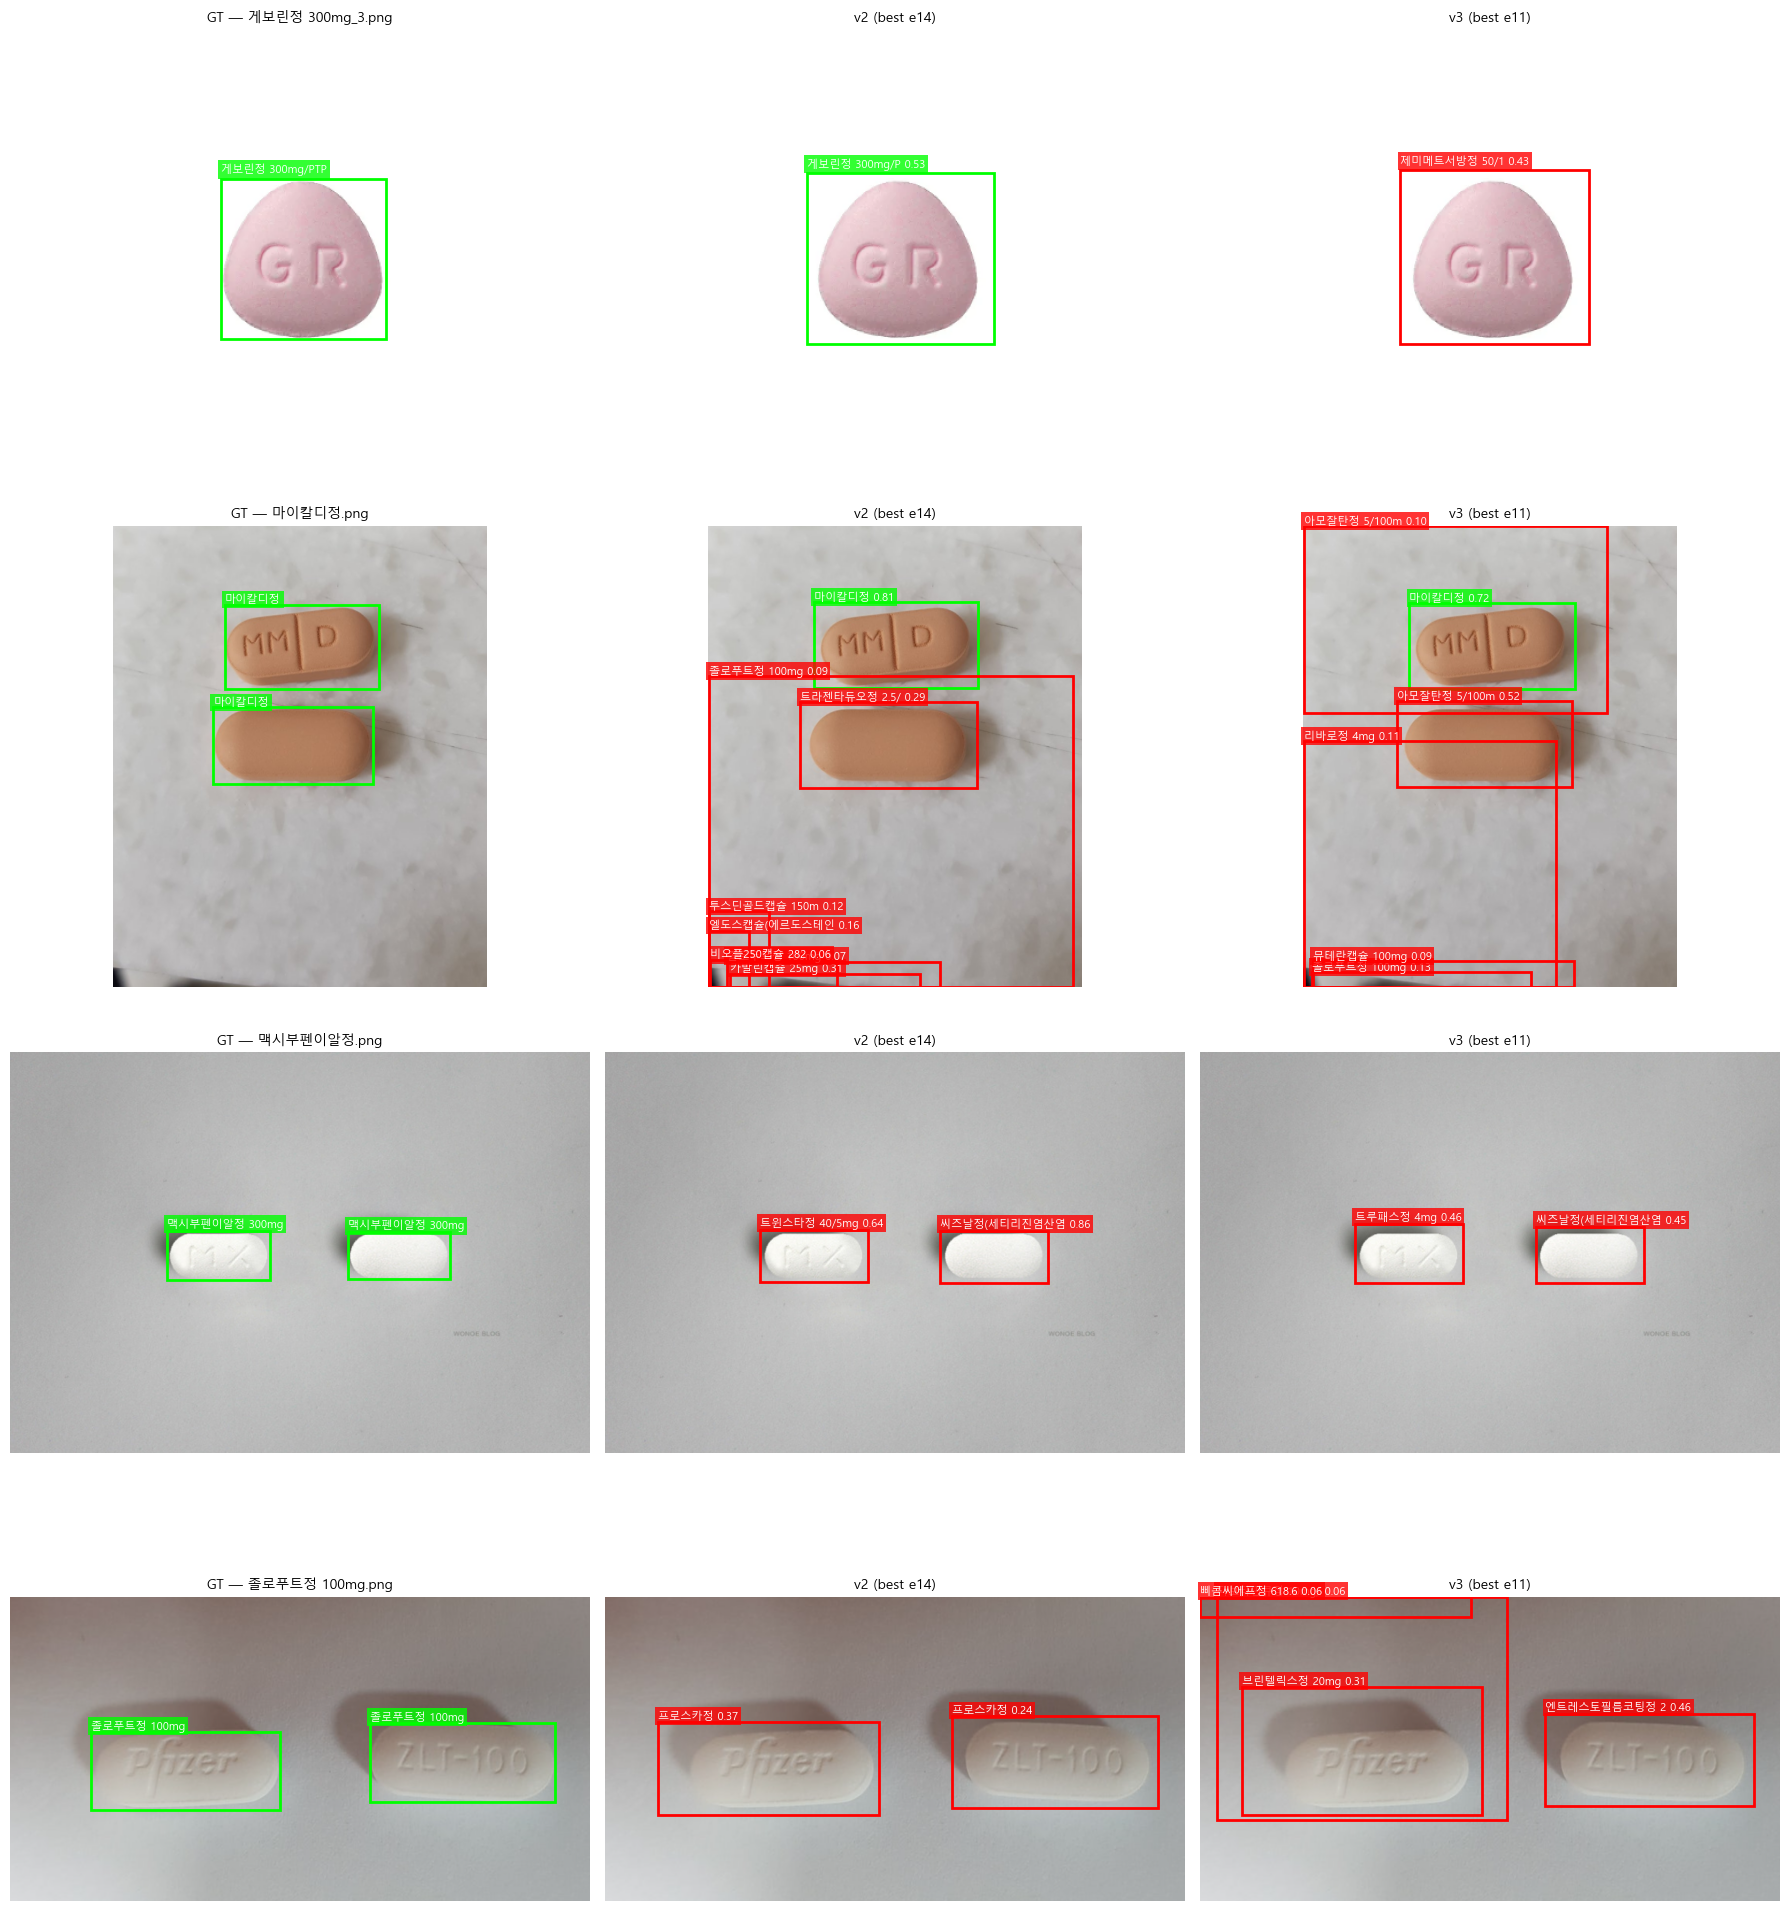

저장: D:\pill_detection\analysis\figures_v3_eval\paper_change.png


In [18]:
import matplotlib.patches as patches
from PIL import Image

EVAL_IMG_DIR = Path(r'D:\pill_detection\eval\test_images')
assert EVAL_IMG_DIR.exists(), f"평가 이미지 폴더 없음: {EVAL_IMG_DIR}"


def get_results_by_filename(data, filename):
    for r in data['results']:
        if r['filename'] == filename:
            return r
    return None


def draw_bbox(ax, bbox, color, label, lw=2):
    x1, y1, x2, y2 = bbox
    rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=lw,
                             edgecolor=color, facecolor='none')
    ax.add_patch(rect)
    ax.text(x1, y1-5, label, color='white', fontsize=8,
            bbox=dict(facecolor=color, alpha=0.8, pad=2, edgecolor='none'))


def visualize_env_change(env_name, v2_env, v3_env, v2_data, v3_data, eval_dir, fig_dir):
    """환경별 v2 vs v3 변화 케이스 시각화 (GT / v2 top1 / v3 top1)."""
    files = sorted({c['filename'] for c in v2_env[env_name]['cases']})
    print(f"{env_name} 환경 이미지: {len(files)}장")

    fig, axes = plt.subplots(len(files), 3, figsize=(18, 5 * len(files)))
    if len(files) == 1:
        axes = axes.reshape(1, -1)

    for row, fname in enumerate(files):
        img = Image.open(eval_dir / fname)
        v2_r = get_results_by_filename(v2_data, fname)
        v3_r = get_results_by_filename(v3_data, fname)

        # 컬럼 1: 원본 + GT
        ax = axes[row, 0]
        ax.imshow(img)
        for gt in v2_r['gt_bboxes']:
            draw_bbox(ax, gt['bbox'], 'lime', nfc(gt['dl_name'])[:15])
        ax.set_title(f'GT — {fname[:25]}', fontsize=10)
        ax.axis('off')

        # 컬럼 2: v2 top-1
        ax = axes[row, 1]
        ax.imshow(img)
        for pred in v2_r['predictions']:
            top1 = nfc(pred['top3_class_name'][0])
            conf = pred['top3_confidence'][0]
            is_correct = False
            for gt in v2_r['gt_bboxes']:
                if iou_xyxy(gt['bbox'], pred['bbox']) >= 0.5 and nfc(gt['dl_name']) == top1:
                    is_correct = True
                    break
            color = 'lime' if is_correct else 'red'
            draw_bbox(ax, pred['bbox'], color, f'{top1[:12]} {conf:.2f}')
        ax.set_title(f"v2 (best e{v2_data['best_epoch']})", fontsize=10)
        ax.axis('off')

        # 컬럼 3: v3 top-1
        ax = axes[row, 2]
        ax.imshow(img)
        for pred in v3_r['predictions']:
            top1 = nfc(pred['top3_class_name'][0])
            conf = pred['top3_confidence'][0]
            is_correct = False
            for gt in v3_r['gt_bboxes']:
                if iou_xyxy(gt['bbox'], pred['bbox']) >= 0.5 and nfc(gt['dl_name']) == top1:
                    is_correct = True
                    break
            color = 'lime' if is_correct else 'red'
            draw_bbox(ax, pred['bbox'], color, f'{top1[:12]} {conf:.2f}')
        ax.set_title(f"v3 (best e{v3_data['best_epoch']})", fontsize=10)
        ax.axis('off')

    plt.tight_layout()
    out_path = fig_dir / f'{env_name}_change.png'
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'저장: {out_path}')


visualize_env_change('paper', v2_env, v3_env, v2_data, v3_data, EVAL_IMG_DIR, FIG_DIR)

palm 환경 이미지: 15장


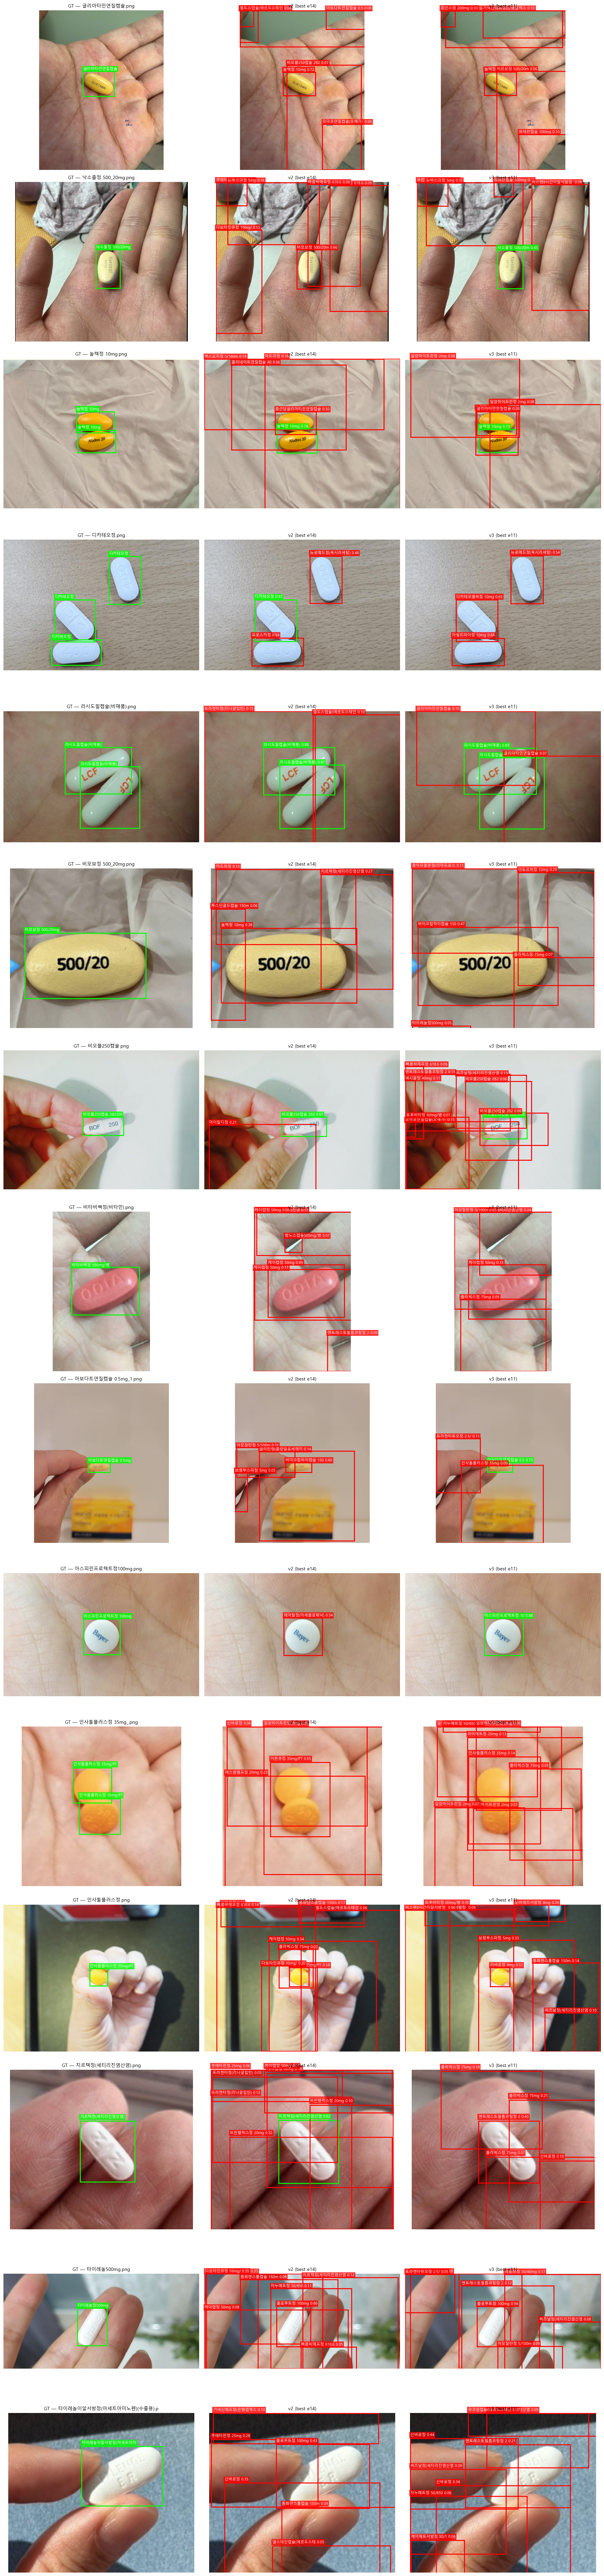

저장: D:\pill_detection\analysis\figures_v3_eval\palm_change.png


In [19]:
# palm 환경 변화 케이스 시각화 (n=20, 가장 큰 환경 + 핵심 가설)
visualize_env_change('palm', v2_env, v3_env, v2_data, v3_data, EVAL_IMG_DIR, FIG_DIR)

## 6. GT 없는 클래스 예측 빈도 (hallucination 변화)

v2 → v3 GT에 없는 클래스 top1 예측 빈도 비교. 학습 사양 변경 + 합성 v3 효과로 hallucination이 줄었는지 확인.

검증 항목:
- v2에서 자주 등장하던 클래스가 v3에서 줄었는지
- v3에서 새로 등장한 hallucination 클래스
- paper 후퇴 케이스의 v3 예측 클래스가 v3 새 hallucination 패턴인지

In [20]:
from collections import Counter

# 33장 GT 정답 클래스 집합
gt_classes = set()
for r in v2_data['results']:
    for gt in r['gt_bboxes']:
        gt_classes.add(nfc(gt['dl_name']))
print(f"33장 GT 정답 클래스 (unique): {len(gt_classes)}개")


def collect_top1_predictions(data):
    """모든 예측 그룹의 top1 클래스 수집 (conf >= 0.05 학습 노트북 기준)."""
    counter = Counter()
    for r in data['results']:
        for pred in r['predictions']:
            top1 = nfc(pred['top3_class_name'][0])
            counter[top1] += 1
    return counter


v2_top1_count = collect_top1_predictions(v2_data)
v3_top1_count = collect_top1_predictions(v3_data)

# v2 / v3 각자 top1 hallucination Top 12 union
v2_non_gt = [(c, n) for c, n in v2_top1_count.most_common() if c not in gt_classes]
v3_non_gt = [(c, n) for c, n in v3_top1_count.most_common() if c not in gt_classes]

print(f"\n=== v2 hallucination Top 10 (GT 없는 클래스 top1 빈도) ===")
print(f"{'클래스':<32s} {'v2':>5s} {'v3':>5s}")
print('-' * 50)
for cls, n in v2_non_gt[:10]:
    v3_n = v3_top1_count.get(cls, 0)
    print(f"{cls[:30]:<32s} {n:>5d} {v3_n:>5d}")

print(f"\n=== v3 hallucination Top 10 (GT 없는 클래스 top1 빈도) ===")
print(f"{'클래스':<32s} {'v2':>5s} {'v3':>5s} {'변화':>8s}")
print('-' * 60)
for cls, n in v3_non_gt[:10]:
    v2_n = v2_top1_count.get(cls, 0)
    delta = '신규' if v2_n == 0 else f'+{n-v2_n}' if n > v2_n else f'{n-v2_n}'
    print(f"{cls[:30]:<32s} {v2_n:>5d} {n:>5d} {delta:>8s}")

print(f"\n=== 합계 ===")
print(f"v2 hallucination 합계: {sum(n for _,n in v2_non_gt)}회")
print(f"v3 hallucination 합계: {sum(n for _,n in v3_non_gt)}회")

33장 GT 정답 클래스 (unique): 31개

=== v2 hallucination Top 10 (GT 없는 클래스 top1 빈도) ===
클래스                                 v2    v3
--------------------------------------------------
엘도스캡슐(에르도스테인)(수출용)                   7     0
이튼큐정 35mg/PTP                        6     0
동화덴스톨캡슐 150mg/PTP                    6     1
투스딘골드캡슐 150mg/PTP                    5     0
프로스카정                                5     0
다보타민큐정 10mg/병                        4     1
삐콤씨에프정 618.6mg/병                     4     2
엑스포지정 5/160mg                        4     0
이가탄에프캡슐 150mg/PTP                    3     3
트라젠타정(리나글립틴)                         3     0

=== v3 hallucination Top 10 (GT 없는 클래스 top1 빈도) ===
클래스                                 v2    v3       변화
------------------------------------------------------------
일양하이트린정 2mg                          1     7       +6
씨즈날정(세티리진염산염)                        1     7       +6
아모잘탄정 5/100mg                        1     6       +5
플라빅스정 75mg                           1     

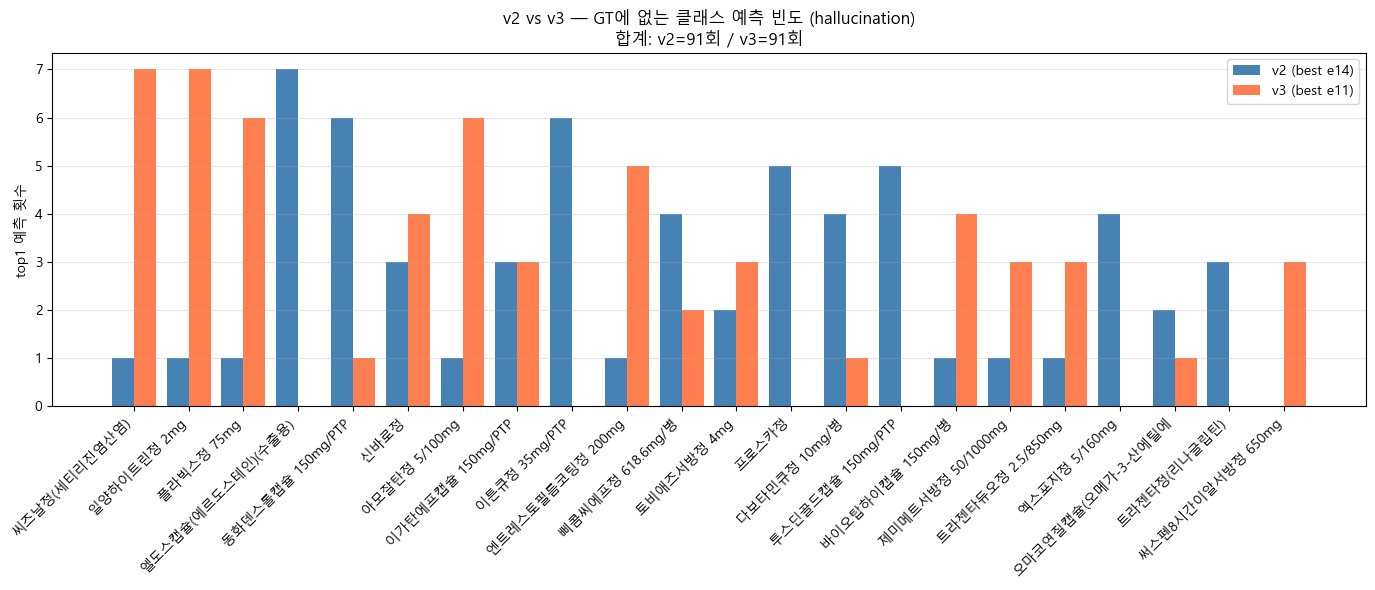

저장: D:\pill_detection\analysis\figures_v3_eval\hallucination_change.png


In [21]:
# v2 vs v3 hallucination 빈도 시각화
top_classes = set([c for c, _ in v2_non_gt[:12]] + [c for c, _ in v3_non_gt[:12]])
top_classes_sorted = sorted(top_classes,
                            key=lambda c: -(v2_top1_count.get(c, 0) + v3_top1_count.get(c, 0)))

x = np.arange(len(top_classes_sorted))
v2_vals = [v2_top1_count.get(c, 0) for c in top_classes_sorted]
v3_vals = [v3_top1_count.get(c, 0) for c in top_classes_sorted]

fig, ax = plt.subplots(figsize=(14, 6))
w = 0.4
ax.bar(x - w/2, v2_vals, w, label=f"v2 (best e{v2_data['best_epoch']})", color='steelblue')
ax.bar(x + w/2, v3_vals, w, label=f"v3 (best e{v3_data['best_epoch']})", color='coral')
ax.set_xticks(x)
ax.set_xticklabels([c[:18] for c in top_classes_sorted], rotation=45, ha='right')
ax.set_ylabel('top1 예측 횟수')
ax.set_title(f'v2 vs v3 — GT에 없는 클래스 예측 빈도 (hallucination)\n'
             f'합계: v2={sum(n for _,n in v2_non_gt)}회 / v3={sum(n for _,n in v3_non_gt)}회')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
out_path = FIG_DIR / 'hallucination_change.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'저장: {out_path}')

## 7. 단일 알약 정확도 (count=1 케이스)

합성 v3 처방: MAX_PILL_AREA_POST 0.50 → 0.20 (거대 알약 차단) + 1개 알약 mean -1.225 (작은 알약 더 많이 합성).

1개 알약 케이스에서 v2 → v3 변화 확인.

In [22]:
# 33장 중 GT 1개인 케이스만 추출
single_pill_files = []
for r in v2_data['results']:
    if len(r['gt_bboxes']) == 1:
        single_pill_files.append(r['filename'])

print(f"단일 알약 이미지: {len(single_pill_files)}장")

# v2 / v3 단일 알약 케이스 채점
v2_single = filter_results(v2_data, set(single_pill_files))
v3_single = filter_results(v3_data, set(single_pill_files))

v2_s_metrics = evaluate_v4_json(v2_single)
v3_s_metrics = evaluate_v4_json(v3_single)

print(f"\n=== 단일 알약 (n={len(single_pill_files)} GT) ===")
print(f"{'측정':<20s} {'v2':>10s} {'v3':>10s} {'Δ':>10s}")
print('-' * 55)
print(f"{'Top-1':<20s} {v2_s_metrics['top1_accuracy']:>9.1%} {v3_s_metrics['top1_accuracy']:>9.1%} "
      f"{(v3_s_metrics['top1_accuracy']-v2_s_metrics['top1_accuracy'])*100:>+8.1f}pp")
print(f"{'Top-3':<20s} {v2_s_metrics['top3_accuracy']:>9.1%} {v3_s_metrics['top3_accuracy']:>9.1%} "
      f"{(v3_s_metrics['top3_accuracy']-v2_s_metrics['top3_accuracy'])*100:>+8.1f}pp")
print(f"{'Detection':<20s} {v2_s_metrics['detection_rate']:>9.1%} {v3_s_metrics['detection_rate']:>9.1%} "
      f"{(v3_s_metrics['detection_rate']-v2_s_metrics['detection_rate'])*100:>+8.1f}pp")
print(f"{'FP':<20s} {v2_s_metrics['n_false_pos']:>10d} {v3_s_metrics['n_false_pos']:>10d}")

# 단일 알약 케이스 verdict 매칭 (각 GT 단위)
print(f"\n=== 단일 알약 케이스 verdict 변화 ===")
print(f"{'filename':<35s} {'GT':<22s} {'v2':<10s} {'v3':<10s} {'변화':<8s}")
print('-' * 95)

# v2/v3 결과를 filename별로 GT 1개씩 매칭
for fname in sorted(single_pill_files):
    v2_r = next(r for r in v2_data['results'] if r['filename'] == fname)
    v3_r = next(r for r in v3_data['results'] if r['filename'] == fname)
    gt = v2_r['gt_bboxes'][0]
    gt_name = nfc(gt['dl_name'])

    def get_verdict(r, gt):
        gt_name = nfc(gt['dl_name'])
        best_iou, best_idx = 0.0, -1
        for j, p in enumerate(r['predictions']):
            i = iou_xyxy(gt['bbox'], p['bbox'])
            if i > best_iou:
                best_iou, best_idx = i, j
        if best_iou < 0.5 or best_idx < 0:
            return 'det_fail'
        top3 = [nfc(n) for n in r['predictions'][best_idx]['top3_class_name']]
        if top3 and top3[0] == gt_name:
            return 'top1'
        elif gt_name in top3:
            return 'top3'
        else:
            return 'wrong'

    v2_v = get_verdict(v2_r, gt)
    v3_v = get_verdict(v3_r, gt)
    rank = {'top1': 3, 'top3': 2, 'wrong': 1, 'det_fail': 0}
    if rank[v3_v] > rank[v2_v]:
        change = '회복 ▲'
    elif rank[v3_v] < rank[v2_v]:
        change = '후퇴 ▼'
    else:
        change = '동일'
    print(f"{fname[:33]:<35s} {gt_name[:20]:<22s} {v2_v:<10s} {v3_v:<10s} {change}")

단일 알약 이미지: 20장

=== 단일 알약 (n=20 GT) ===
측정                           v2         v3          Δ
-------------------------------------------------------
Top-1                    35.0%     40.0%     +5.0pp
Top-3                    65.0%     60.0%     -5.0pp
Detection               100.0%    100.0%     +0.0pp
FP                           74         72

=== 단일 알약 케이스 verdict 변화 ===
filename                            GT                     v2         v3         변화      
-----------------------------------------------------------------------------------------------
게보린정 300mg_3.png                    게보린정 300mg/PTP         top1       top3       후퇴 ▼
글리아타민연질캡슐.png                       글리아타민연질캡슐              top3       wrong      후퇴 ▼
낙소졸정 500_20mg.png                   낙소졸정 500/20mg          top3       top1       회복 ▲
넥시움정 40mg.png                       넥시움정 40mg              wrong      wrong      동일
노바스크정 5mg.png                       노바스크정 5mg              top1       top1       동일
뮤테란캡슐 100

## 8. count별 정답률 + 페어 1/2/3 라벨 이동

count별: 1개 / 2개 / 3-4개 알약 케이스 정답률 변화. 합성 v3 카운트 가중 + MAX_PILL_AREA 0.20 효과.

페어 라벨 이동: 백본 한계 70 케이스 cos_sim 0.992 (세션 46 기록). v3에서 변화 거의 없을 것으로 예상.
- 페어 1: 동아오팔몬↔리피토
- 페어 2: 디카테오엘씨↔디카테오 (같은 약물군)
- 페어 3: 비유피-4↔베시케어

In [23]:
from collections import defaultdict

# count별 정답률
count_stats = defaultdict(lambda: {'v2_top1': 0, 'v2_top3': 0, 'v2_match': 0,
                                    'v3_top1': 0, 'v3_top3': 0, 'v3_match': 0,
                                    'n_gt': 0})


def add_to_count_stats(data, key_prefix):
    for r in data['results']:
        n_pill = len(r['gt_bboxes'])
        # 1개 / 2개 / 3-4개 그룹화
        if n_pill == 1:
            grp = '1개'
        elif n_pill == 2:
            grp = '2개'
        else:
            grp = '3-4개'

        used = set()
        for gt in r['gt_bboxes']:
            if key_prefix == 'v2':
                count_stats[grp]['n_gt'] += 1  # 한번만 카운트
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(r['predictions']):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou >= 0.5 and best_idx >= 0:
                used.add(best_idx)
                count_stats[grp][f'{key_prefix}_match'] += 1
                top3 = [nfc(n) for n in r['predictions'][best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    count_stats[grp][f'{key_prefix}_top1'] += 1
                elif gt_name in top3:
                    count_stats[grp][f'{key_prefix}_top3'] += 1


add_to_count_stats(v2_data, 'v2')
add_to_count_stats(v3_data, 'v3')

print(f"=== count별 정답률 ===")
print(f"{'그룹':<10s} {'n_GT':>6s} | {'v2 Top-1':>10s} {'v3 Top-1':>10s} {'Δ':>8s} | "
      f"{'v2 Top-3':>10s} {'v3 Top-3':>10s} {'Δ':>8s}")
print('-' * 90)
for grp in ['1개', '2개', '3-4개']:
    s = count_stats[grp]
    n = s['n_gt']
    if n == 0:
        continue
    v2_t1 = s['v2_top1'] / n
    v3_t1 = s['v3_top1'] / n
    # Top-3 누적
    v2_t3 = (s['v2_top1'] + s['v2_top3']) / n
    v3_t3 = (s['v3_top1'] + s['v3_top3']) / n
    print(f"{grp:<10s} {n:>6d} | {v2_t1:>9.1%}  {v3_t1:>9.1%}  {(v3_t1-v2_t1)*100:>+7.1f}pp | "
          f"{v2_t3:>9.1%}  {v3_t3:>9.1%}  {(v3_t3-v2_t3)*100:>+7.1f}pp")

=== count별 정답률 ===
그룹           n_GT |   v2 Top-1   v3 Top-1        Δ |   v2 Top-3   v3 Top-3        Δ
------------------------------------------------------------------------------------------
1개             20 |     35.0%      40.0%     +5.0pp |     65.0%      60.0%     -5.0pp
2개             24 |     29.2%      25.0%     -4.2pp |     37.5%      54.2%    +16.7pp
3-4개            3 |     33.3%       0.0%    -33.3pp |    100.0%      33.3%    -66.7pp


In [24]:
# 페어 1/2/3 라벨 이동 패턴
pairs = {
    '페어 1 (동아오팔몬↔리피토)': ('동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)', '리피토정 20mg'),
    '페어 2 (디카테오엘씨↔디카테오)': ('디카테오엘씨정 10mg/병', '디카테오정'),
    '페어 3 (비유피-4↔베시케어)': ('비유피-4정 20mg', '베시케어정 10mg'),
}


def check_pair_movement(data, gt_name_a, gt_name_b):
    """GT가 클래스 A인데 top1이 B로 잘못 가는 케이스 + 그 반대 카운트."""
    gt_a_to_b = 0  # GT=A, top1=B
    gt_b_to_a = 0  # GT=B, top1=A
    gt_a_correct = 0
    gt_b_correct = 0
    gt_a_total = 0
    gt_b_total = 0

    a_nfc = nfc(gt_name_a)
    b_nfc = nfc(gt_name_b)

    for r in data['results']:
        for gt in r['gt_bboxes']:
            gt_n = nfc(gt['dl_name'])
            if gt_n not in (a_nfc, b_nfc):
                continue
            # GT 매칭 예측 찾기
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(r['predictions']):
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou < 0.5 or best_idx < 0:
                continue
            top1 = nfc(r['predictions'][best_idx]['top3_class_name'][0])

            if gt_n == a_nfc:
                gt_a_total += 1
                if top1 == a_nfc:
                    gt_a_correct += 1
                elif top1 == b_nfc:
                    gt_a_to_b += 1
            else:  # gt_n == b_nfc
                gt_b_total += 1
                if top1 == b_nfc:
                    gt_b_correct += 1
                elif top1 == a_nfc:
                    gt_b_to_a += 1

    return {
        'a_total': gt_a_total, 'a_correct': gt_a_correct, 'a_to_b': gt_a_to_b,
        'b_total': gt_b_total, 'b_correct': gt_b_correct, 'b_to_a': gt_b_to_a,
    }


print(f"=== 페어 1/2/3 라벨 이동 패턴 (GT 단위) ===\n")
for pair_name, (a, b) in pairs.items():
    v2_p = check_pair_movement(v2_data, a, b)
    v3_p = check_pair_movement(v3_data, a, b)
    print(f"{pair_name}")
    print(f"  GT=A ({a[:25]}): n={v2_p['a_total']} (v2/v3 동일)")
    if v2_p['a_total'] > 0:
        print(f"    A→A 정답: v2 {v2_p['a_correct']} / v3 {v3_p['a_correct']}")
        print(f"    A→B 라벨이동: v2 {v2_p['a_to_b']} / v3 {v3_p['a_to_b']}")
    print(f"  GT=B ({b[:25]}): n={v2_p['b_total']}")
    if v2_p['b_total'] > 0:
        print(f"    B→B 정답: v2 {v2_p['b_correct']} / v3 {v3_p['b_correct']}")
        print(f"    B→A 라벨이동: v2 {v2_p['b_to_a']} / v3 {v3_p['b_to_a']}")
    print()

=== 페어 1/2/3 라벨 이동 패턴 (GT 단위) ===

페어 1 (동아오팔몬↔리피토)
  GT=A (동아오팔몬정(리마프로스트알파-시클로덱스트린포접): n=0 (v2/v3 동일)
  GT=B (리피토정 20mg): n=0

페어 2 (디카테오엘씨↔디카테오)
  GT=A (디카테오엘씨정 10mg/병): n=0 (v2/v3 동일)
  GT=B (디카테오정): n=3
    B→B 정답: v2 1 / v3 0
    B→A 라벨이동: v2 0 / v3 1

페어 3 (비유피-4↔베시케어)
  GT=A (비유피-4정 20mg): n=0 (v2/v3 동일)
  GT=B (베시케어정 10mg): n=0



## 7. 3-way 모델 비교 (baseline / v2 / v3)

같은 33장 평가셋(47 GT)에 대해 3개 모델 누가 더 잘 맞추나 메타데이터 + 시각화.
- baseline (e15, 합성 통합본)
- v2 (e14, 합성 v2 강화)  
- v3 (e11, 합성 v3 강화)

확인 항목:
- 메인 비교표 (Top-1 / Top-3 / Det / FP / ms_per_image)
- 47 GT 단위 verdict 분포 시각화
- 47 GT 단위 어느 모델이 맞췄나 (단독 정답 / 공통 정답)

baseline: best_epoch=15, num_gt=47

=== 메인 비교표 (33장, 47 GT) ===
측정                       baseline           v2           v3
------------------------------------------------------------
Top-1                      29.8%       31.9%       29.8%
Top-3                      40.4%       53.2%       55.3%
Detection                  95.7%       95.7%       93.6%
Image Top-1                27.3%       24.2%       27.3%
Image Top-3                36.4%       48.5%       48.5%
False Positive                259          100           99
best_epoch                     15           14           11
ms/image                    125.5        128.6        132.1

=== 47 GT 단위 Top-1 정답 분포 ===
baseline 단독: 3
v2 단독:       2
v3 단독:       1
baseline+v2 (v3 X): 2
baseline+v3 (v2 X): 2
v2+v3 (baseline X): 4
3개 모두 정답:      7
3개 모두 오답:      26


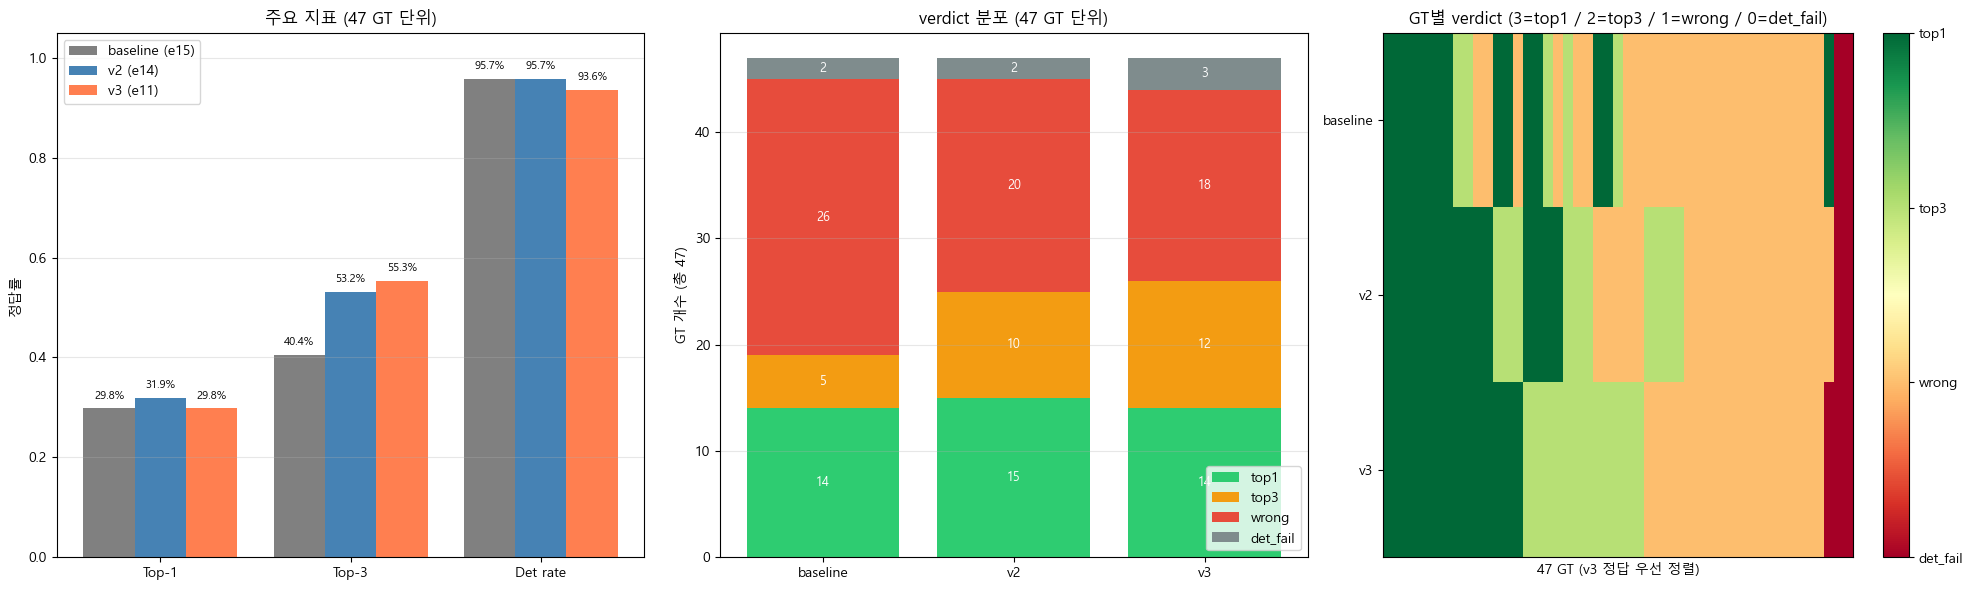


저장: D:\pill_detection\analysis\figures_v3_eval\3way_comparison.png


In [25]:
# baseline 결과 추가 로드
with open(BASELINE_RESULT, encoding='utf-8') as f:
    baseline_data = json.load(f)

print(f"baseline: best_epoch={baseline_data['best_epoch']}, num_gt={baseline_data['num_gt_bboxes']}")

# 3개 모델 채점
b_metrics = evaluate_v4_json(baseline_data)
v2_metrics = evaluate_v4_json(v2_data)
v3_metrics = evaluate_v4_json(v3_data)


# ────── 메인 비교표 ──────
print(f"\n=== 메인 비교표 (33장, 47 GT) ===")
print(f"{'측정':<20s} {'baseline':>12s} {'v2':>12s} {'v3':>12s}")
print('-' * 60)
print(f"{'Top-1':<20s} {b_metrics['top1_accuracy']:>11.1%} {v2_metrics['top1_accuracy']:>11.1%} {v3_metrics['top1_accuracy']:>11.1%}")
print(f"{'Top-3':<20s} {b_metrics['top3_accuracy']:>11.1%} {v2_metrics['top3_accuracy']:>11.1%} {v3_metrics['top3_accuracy']:>11.1%}")
print(f"{'Detection':<20s} {b_metrics['detection_rate']:>11.1%} {v2_metrics['detection_rate']:>11.1%} {v3_metrics['detection_rate']:>11.1%}")
print(f"{'Image Top-1':<20s} {b_metrics['image_top1']:>11.1%} {v2_metrics['image_top1']:>11.1%} {v3_metrics['image_top1']:>11.1%}")
print(f"{'Image Top-3':<20s} {b_metrics['image_top3']:>11.1%} {v2_metrics['image_top3']:>11.1%} {v3_metrics['image_top3']:>11.1%}")
print(f"{'False Positive':<20s} {b_metrics['n_false_pos']:>12d} {v2_metrics['n_false_pos']:>12d} {v3_metrics['n_false_pos']:>12d}")
print(f"{'best_epoch':<20s} {baseline_data['best_epoch']:>12d} {v2_data['best_epoch']:>12d} {v3_data['best_epoch']:>12d}")
print(f"{'ms/image':<20s} {baseline_data.get('ms_per_image', 0):>12.1f} {v2_data.get('ms_per_image', 0):>12.1f} {v3_data.get('ms_per_image', 0):>12.1f}")


# ────── 47 GT 단위 verdict 매칭 ──────
def get_verdict_per_gt(data):
    """{(filename, gt_idx): verdict} 반환."""
    result = {}
    for r in data['results']:
        used = set()
        for gt_idx, gt in enumerate(r['gt_bboxes']):
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(r['predictions']):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou < 0.5 or best_idx < 0:
                verdict = 'det_fail'
            else:
                used.add(best_idx)
                top3 = [nfc(n) for n in r['predictions'][best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    verdict = 'top1'
                elif gt_name in top3:
                    verdict = 'top3'
                else:
                    verdict = 'wrong'
            result[(r['filename'], gt_idx)] = verdict
    return result


b_verdicts = get_verdict_per_gt(baseline_data)
v2_verdicts = get_verdict_per_gt(v2_data)
v3_verdicts = get_verdict_per_gt(v3_data)

# 정답(top1) 단위 어느 모델이 맞췄나
gt_keys = sorted(b_verdicts.keys())
b_top1 = {k for k, v in b_verdicts.items() if v == 'top1'}
v2_top1 = {k for k, v in v2_verdicts.items() if v == 'top1'}
v3_top1 = {k for k, v in v3_verdicts.items() if v == 'top1'}

print(f"\n=== 47 GT 단위 Top-1 정답 분포 ===")
print(f"baseline 단독: {len(b_top1 - v2_top1 - v3_top1)}")
print(f"v2 단독:       {len(v2_top1 - b_top1 - v3_top1)}")
print(f"v3 단독:       {len(v3_top1 - b_top1 - v2_top1)}")
print(f"baseline+v2 (v3 X): {len((b_top1 & v2_top1) - v3_top1)}")
print(f"baseline+v3 (v2 X): {len((b_top1 & v3_top1) - v2_top1)}")
print(f"v2+v3 (baseline X): {len((v2_top1 & v3_top1) - b_top1)}")
print(f"3개 모두 정답:      {len(b_top1 & v2_top1 & v3_top1)}")
print(f"3개 모두 오답:      {len(set(gt_keys) - b_top1 - v2_top1 - v3_top1)}")


# ────── 시각화 ──────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# (1) 메인 지표 막대그래프
ax = axes[0]
metrics_names = ['Top-1', 'Top-3', 'Det rate']
b_vals = [b_metrics['top1_accuracy'], b_metrics['top3_accuracy'], b_metrics['detection_rate']]
v2_vals = [v2_metrics['top1_accuracy'], v2_metrics['top3_accuracy'], v2_metrics['detection_rate']]
v3_vals = [v3_metrics['top1_accuracy'], v3_metrics['top3_accuracy'], v3_metrics['detection_rate']]

x = np.arange(len(metrics_names))
w = 0.27
ax.bar(x - w, b_vals, w, label=f"baseline (e{baseline_data['best_epoch']})", color='gray')
ax.bar(x,     v2_vals, w, label=f"v2 (e{v2_data['best_epoch']})", color='steelblue')
ax.bar(x + w, v3_vals, w, label=f"v3 (e{v3_data['best_epoch']})", color='coral')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.set_ylabel('정답률')
ax.set_ylim(0, 1.05)
ax.set_title('주요 지표 (47 GT 단위)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for i, (b, v2, v3) in enumerate(zip(b_vals, v2_vals, v3_vals)):
    ax.text(i - w, b + 0.02, f'{b:.1%}', ha='center', fontsize=8)
    ax.text(i,     v2 + 0.02, f'{v2:.1%}', ha='center', fontsize=8)
    ax.text(i + w, v3 + 0.02, f'{v3:.1%}', ha='center', fontsize=8)

# (2) verdict 분포 stacked bar
ax = axes[1]
verdict_order = ['top1', 'top3', 'wrong', 'det_fail']
colors = ['#2ecc71', '#f39c12', '#e74c3c', '#7f8c8d']

def count_verdicts(verdicts):
    return [sum(1 for v in verdicts.values() if v == vd) for vd in verdict_order]

b_counts = count_verdicts(b_verdicts)
v2_counts = count_verdicts(v2_verdicts)
v3_counts = count_verdicts(v3_verdicts)

models = ['baseline', 'v2', 'v3']
bottom = np.zeros(3)
for i, vd in enumerate(verdict_order):
    vals = [b_counts[i], v2_counts[i], v3_counts[i]]
    ax.bar(models, vals, bottom=bottom, label=vd, color=colors[i])
    for j, val in enumerate(vals):
        if val > 0:
            ax.text(j, bottom[j] + val/2, f'{val}', ha='center', va='center', fontsize=9, color='white')
    bottom += vals
ax.set_ylabel('GT 개수 (총 47)')
ax.set_title('verdict 분포 (47 GT 단위)')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)

# (3) 47 GT × 3 모델 verdict heatmap
ax = axes[2]
verdict_to_int = {'top1': 3, 'top3': 2, 'wrong': 1, 'det_fail': 0}
matrix = np.array([
    [verdict_to_int[b_verdicts[k]] for k in gt_keys],
    [verdict_to_int[v2_verdicts[k]] for k in gt_keys],
    [verdict_to_int[v3_verdicts[k]] for k in gt_keys],
])

# v3 top1 우선 → v2 top1 → baseline top1 순으로 정렬 (시각 패턴 보기)
sort_idx = np.lexsort((matrix[0], matrix[1], matrix[2]))[::-1]
matrix_sorted = matrix[:, sort_idx]

im = ax.imshow(matrix_sorted, aspect='auto', cmap='RdYlGn', vmin=0, vmax=3)
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(['baseline', 'v2', 'v3'])
ax.set_xticks([])
ax.set_xlabel('47 GT (v3 정답 우선 정렬)')
ax.set_title('GT별 verdict (3=top1 / 2=top3 / 1=wrong / 0=det_fail)')

cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(['det_fail', 'wrong', 'top3', 'top1'])

plt.tight_layout()
out_path = FIG_DIR / '3way_comparison.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'\n저장: {out_path}')

## 9. v2 + v3 ensemble + conf threshold 튜닝 (재학습 X)

학습 도는 동안 병렬 작업. v2/v3 추론 결과 JSON 두 개로:
- ensemble: bbox 매칭 후 conf 평균 (또는 max), top1/top3 voting
- conf threshold: 0.05 → 0.1 / 0.15 / 0.2 / 0.3 sweep, FP vs Det 트레이드오프

목표: v2(31.9%) 또는 v3(29.8%) 단독 대비 일반화 성능 개선 가능한지 데이터로 확인.

In [26]:
def evaluate_with_conf_threshold(data, conf_thr=0.05, iou_thr=0.5):
    """conf threshold 적용해서 채점. 학습 노트북 기본 conf=0.05 → 다른 값으로 변경 시 효과 측정."""
    n_top1 = n_top3 = n_match = 0
    n_false_pos = 0
    total_gt = sum(len(r['gt_bboxes']) for r in data['results'])

    for r in data['results']:
        # conf threshold 통과한 prediction만 사용
        # (conf는 top3_confidence[0] = top1 confidence로 판단)
        preds = [p for p in r['predictions'] if p['top3_confidence'][0] >= conf_thr]

        used = set()
        for gt in r['gt_bboxes']:
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(preds):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j

            if best_iou >= iou_thr and best_idx >= 0:
                n_match += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in preds[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    n_top1 += 1
                if gt_name in top3:
                    n_top3 += 1

        n_false_pos += len(preds) - len(used)

    return {
        'top1': n_top1 / total_gt,
        'top3': n_top3 / total_gt,
        'det':  n_match / total_gt,
        'fp':   n_false_pos,
    }


# v2 / v3 conf sweep
conf_levels = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]

print(f"=== conf threshold sweep (47 GT) ===")
print(f"{'conf':>6s} | {'v2 Top-1':>10s} {'v2 Top-3':>10s} {'v2 Det':>8s} {'v2 FP':>7s} | "
      f"{'v3 Top-1':>10s} {'v3 Top-3':>10s} {'v3 Det':>8s} {'v3 FP':>7s}")
print('-' * 110)
for c in conf_levels:
    v2_m = evaluate_with_conf_threshold(v2_data, conf_thr=c)
    v3_m = evaluate_with_conf_threshold(v3_data, conf_thr=c)
    print(f"{c:>6.2f} | {v2_m['top1']:>9.1%}  {v2_m['top3']:>9.1%}  {v2_m['det']:>7.1%}  {v2_m['fp']:>6d} | "
          f"{v3_m['top1']:>9.1%}  {v3_m['top3']:>9.1%}  {v3_m['det']:>7.1%}  {v3_m['fp']:>6d}")

=== conf threshold sweep (47 GT) ===
  conf |   v2 Top-1   v2 Top-3   v2 Det   v2 FP |   v3 Top-1   v3 Top-3   v3 Det   v3 FP
--------------------------------------------------------------------------------------------------------------
  0.05 |     31.9%      53.2%    95.7%     100 |     29.8%      55.3%    93.6%      99
  0.10 |     31.9%      53.2%    95.7%      54 |     29.8%      55.3%    93.6%      48
  0.15 |     31.9%      53.2%    95.7%      39 |     29.8%      55.3%    93.6%      28
  0.20 |     31.9%      53.2%    95.7%      26 |     29.8%      55.3%    93.6%      21
  0.30 |     31.9%      53.2%    91.5%      13 |     29.8%      53.2%    89.4%      14
  0.40 |     31.9%      51.1%    85.1%       3 |     29.8%      53.2%    83.0%       4


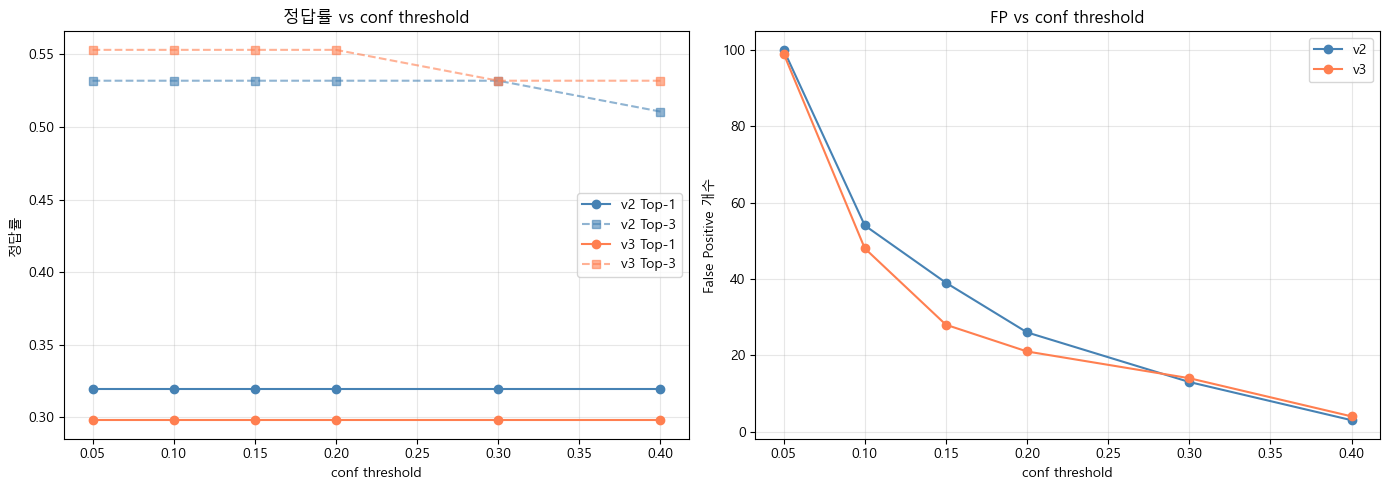

저장: D:\pill_detection\analysis\figures_v3_eval\conf_threshold_sweep.png


In [27]:
# conf sweep 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# v2/v3 각각 라인
for ax_idx, (data, label, color) in enumerate([(v2_data, 'v2', 'steelblue'), (v3_data, 'v3', 'coral')]):
    metrics = [evaluate_with_conf_threshold(data, conf_thr=c) for c in conf_levels]

    # 좌: 정답률 변화
    ax = axes[0]
    ax.plot(conf_levels, [m['top1'] for m in metrics], 'o-', color=color, label=f'{label} Top-1')
    ax.plot(conf_levels, [m['top3'] for m in metrics], 's--', color=color, label=f'{label} Top-3', alpha=0.6)

    # 우: FP 변화
    ax = axes[1]
    ax.plot(conf_levels, [m['fp'] for m in metrics], 'o-', color=color, label=label)

axes[0].set_xlabel('conf threshold')
axes[0].set_ylabel('정답률')
axes[0].set_title('정답률 vs conf threshold')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_xlabel('conf threshold')
axes[1].set_ylabel('False Positive 개수')
axes[1].set_title('FP vs conf threshold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
out_path = FIG_DIR / 'conf_threshold_sweep.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'저장: {out_path}')

## 10. v2 + v3 ensemble

두 모델 추론 결과 합치는 두 가지 방식 시도:

**방식 A — bbox 매칭 + conf 평균**:
- v2 prediction과 v3 prediction을 IoU>=0.5로 매칭
- 매칭된 쌍은 bbox 평균 + conf 평균 + top3 클래스 합집합 (conf 가중)
- 매칭 안 된 unique prediction은 그대로 유지 (단 conf threshold로 필터링)

**방식 B — top3 voting**:
- 동일 bbox 영역에서 v2 top1 + v3 top1이 같으면 그대로 (확신 강함)
- 다르면 v2 top3 ∪ v3 top3 합집합에서 conf 합 기준 top1 선택
- top3은 합집합 conf 합 기준 상위 3

데이터 근거:
- v2/v3 모두 conf 0.2 컷 시 정답률 변화 없음 → ensemble 입력으로 0.2 컷 사용
- v2/v3 hallucination 분포 다름 (212 vs 91회) → 합칠 때 분산 감소 가능

In [28]:
def merge_predictions_avg(v2_preds, v3_preds, conf_thr=0.2, iou_match=0.5):
    """방식 A: IoU 매칭 후 conf 평균. unique prediction은 conf threshold만 통과시 유지."""
    # conf threshold 적용
    v2_filt = [p for p in v2_preds if p['top3_confidence'][0] >= conf_thr]
    v3_filt = [p for p in v3_preds if p['top3_confidence'][0] >= conf_thr]

    merged = []
    used_v3 = set()

    for p2 in v2_filt:
        # v3 prediction 중 IoU 매칭 찾기
        best_iou, best_idx = 0.0, -1
        for j, p3 in enumerate(v3_filt):
            if j in used_v3:
                continue
            i = iou_xyxy(p2['bbox'], p3['bbox'])
            if i > best_iou:
                best_iou, best_idx = i, j

        if best_iou >= iou_match and best_idx >= 0:
            # 매칭된 쌍 — bbox 평균 + top3 합집합 (conf 가중 합)
            p3 = v3_filt[best_idx]
            used_v3.add(best_idx)

            # bbox 평균
            avg_bbox = [(p2['bbox'][k] + p3['bbox'][k]) / 2 for k in range(4)]

            # top3 클래스 conf 합산
            conf_acc = {}
            for cls, c in zip(p2['top3_class_name'], p2['top3_confidence']):
                cls_n = nfc(cls)
                conf_acc[cls_n] = conf_acc.get(cls_n, 0) + c
            for cls, c in zip(p3['top3_class_name'], p3['top3_confidence']):
                cls_n = nfc(cls)
                conf_acc[cls_n] = conf_acc.get(cls_n, 0) + c

            # 상위 3
            top3_sorted = sorted(conf_acc.items(), key=lambda x: -x[1])[:3]
            merged.append({
                'bbox': avg_bbox,
                'top3_class_name': [c for c, _ in top3_sorted],
                'top3_confidence': [c / 2 for _, c in top3_sorted],  # 평균
            })
        else:
            # v2 unique
            merged.append(p2)

    # v3 unique (매칭 안 된 것)
    for j, p3 in enumerate(v3_filt):
        if j not in used_v3:
            merged.append(p3)

    return merged


def merge_predictions_vote(v2_preds, v3_preds, conf_thr=0.2, iou_match=0.5):
    """방식 B: top1 일치 시 그대로, 다르면 top3 합집합에서 conf 합 기준 재선정."""
    v2_filt = [p for p in v2_preds if p['top3_confidence'][0] >= conf_thr]
    v3_filt = [p for p in v3_preds if p['top3_confidence'][0] >= conf_thr]

    merged = []
    used_v3 = set()

    for p2 in v2_filt:
        best_iou, best_idx = 0.0, -1
        for j, p3 in enumerate(v3_filt):
            if j in used_v3:
                continue
            i = iou_xyxy(p2['bbox'], p3['bbox'])
            if i > best_iou:
                best_iou, best_idx = i, j

        if best_iou >= iou_match and best_idx >= 0:
            p3 = v3_filt[best_idx]
            used_v3.add(best_idx)

            v2_top1 = nfc(p2['top3_class_name'][0])
            v3_top1 = nfc(p3['top3_class_name'][0])

            avg_bbox = [(p2['bbox'][k] + p3['bbox'][k]) / 2 for k in range(4)]

            if v2_top1 == v3_top1:
                # 일치 → 그대로 (conf 평균)
                conf_avg = (p2['top3_confidence'][0] + p3['top3_confidence'][0]) / 2
                # top3 합집합 conf 합 기준
                conf_acc = {}
                for cls, c in zip(p2['top3_class_name'], p2['top3_confidence']):
                    conf_acc[nfc(cls)] = conf_acc.get(nfc(cls), 0) + c
                for cls, c in zip(p3['top3_class_name'], p3['top3_confidence']):
                    conf_acc[nfc(cls)] = conf_acc.get(nfc(cls), 0) + c
                top3_sorted = sorted(conf_acc.items(), key=lambda x: -x[1])[:3]
                merged.append({
                    'bbox': avg_bbox,
                    'top3_class_name': [c for c, _ in top3_sorted],
                    'top3_confidence': [c / 2 for _, c in top3_sorted],
                })
            else:
                # 불일치 → top3 합집합 conf 합 기준 재선정
                conf_acc = {}
                for cls, c in zip(p2['top3_class_name'], p2['top3_confidence']):
                    conf_acc[nfc(cls)] = conf_acc.get(nfc(cls), 0) + c
                for cls, c in zip(p3['top3_class_name'], p3['top3_confidence']):
                    conf_acc[nfc(cls)] = conf_acc.get(nfc(cls), 0) + c
                top3_sorted = sorted(conf_acc.items(), key=lambda x: -x[1])[:3]
                merged.append({
                    'bbox': avg_bbox,
                    'top3_class_name': [c for c, _ in top3_sorted],
                    'top3_confidence': [c / 2 for _, c in top3_sorted],
                })
        else:
            merged.append(p2)

    for j, p3 in enumerate(v3_filt):
        if j not in used_v3:
            merged.append(p3)

    return merged


def evaluate_ensemble(v2_data, v3_data, merge_fn, conf_thr=0.2, iou_thr=0.5):
    """v2/v3 prediction을 merge_fn으로 합치고 채점."""
    n_top1 = n_top3 = n_match = n_false_pos = 0
    total_gt = sum(len(r['gt_bboxes']) for r in v2_data['results'])

    # filename → results map
    v3_map = {r['filename']: r for r in v3_data['results']}

    for r in v2_data['results']:
        v3_r = v3_map[r['filename']]
        merged_preds = merge_fn(r['predictions'], v3_r['predictions'], conf_thr=conf_thr)

        used = set()
        for gt in r['gt_bboxes']:
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(merged_preds):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou >= iou_thr and best_idx >= 0:
                n_match += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in merged_preds[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    n_top1 += 1
                if gt_name in top3:
                    n_top3 += 1
        n_false_pos += len(merged_preds) - len(used)

    return {'top1': n_top1/total_gt, 'top3': n_top3/total_gt,
            'det': n_match/total_gt, 'fp': n_false_pos}


# ────── 비교표 ──────
print(f"=== ensemble 비교 (47 GT, conf=0.2) ===")
print(f"{'방식':<30s} {'Top-1':>8s} {'Top-3':>8s} {'Det':>8s} {'FP':>6s}")
print('-' * 70)

# 단독 (conf 0.2)
v2_alone = evaluate_with_conf_threshold(v2_data, conf_thr=0.2)
v3_alone = evaluate_with_conf_threshold(v3_data, conf_thr=0.2)
print(f"{'v2 단독 (conf 0.2)':<30s} {v2_alone['top1']:>7.1%} {v2_alone['top3']:>7.1%} {v2_alone['det']:>7.1%} {v2_alone['fp']:>6d}")
print(f"{'v3 단독 (conf 0.2)':<30s} {v3_alone['top1']:>7.1%} {v3_alone['top3']:>7.1%} {v3_alone['det']:>7.1%} {v3_alone['fp']:>6d}")

# ensemble
ens_avg = evaluate_ensemble(v2_data, v3_data, merge_predictions_avg, conf_thr=0.2)
print(f"{'ensemble A (conf 평균)':<30s} {ens_avg['top1']:>7.1%} {ens_avg['top3']:>7.1%} {ens_avg['det']:>7.1%} {ens_avg['fp']:>6d}")

ens_vote = evaluate_ensemble(v2_data, v3_data, merge_predictions_vote, conf_thr=0.2)
print(f"{'ensemble B (top3 voting)':<30s} {ens_vote['top1']:>7.1%} {ens_vote['top3']:>7.1%} {ens_vote['det']:>7.1%} {ens_vote['fp']:>6d}")

=== ensemble 비교 (47 GT, conf=0.2) ===
방식                                Top-1    Top-3      Det     FP
----------------------------------------------------------------------
v2 단독 (conf 0.2)                 31.9%   53.2%   95.7%     26
v3 단독 (conf 0.2)                 29.8%   55.3%   93.6%     21
ensemble A (conf 평균)             36.2%   55.3%   95.7%     33
ensemble B (top3 voting)         36.2%   55.3%   95.7%     33


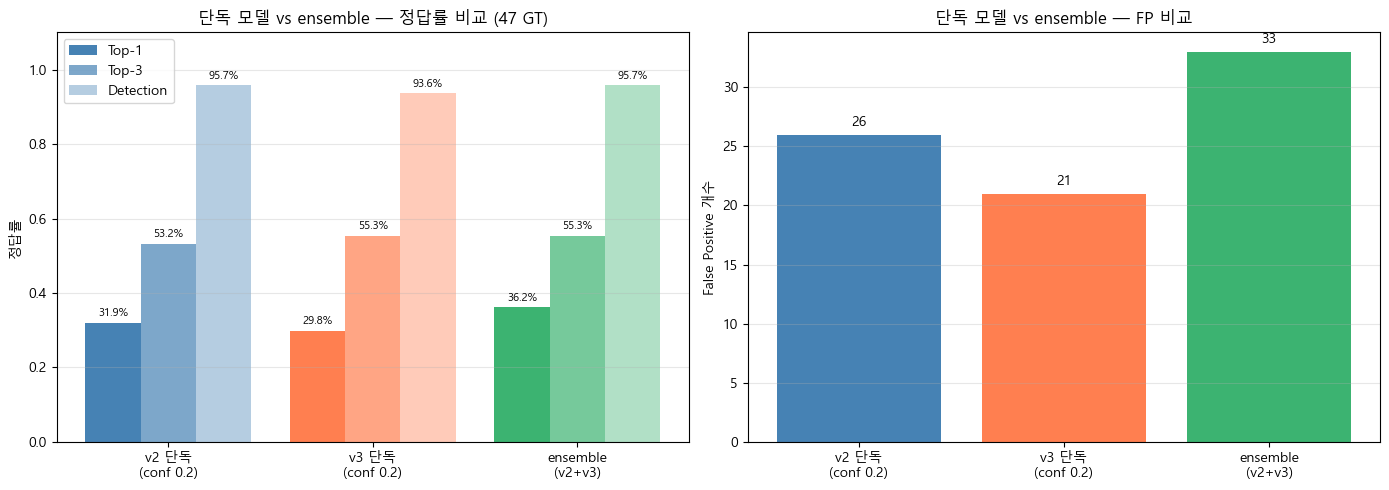

저장: D:\pill_detection\analysis\figures_v3_eval\ensemble_comparison.png

=== 핵심 결과 ===
Top-1 변화: v2 단독 31.9% → ensemble 36.2% (+4.3pp)
Detection 유지: 95.7% → 95.7%
FP: v2 26 → ensemble 33


In [29]:
# ensemble 결과 시각화 (보고서/발표용)
import numpy as np

methods = ['v2 단독\n(conf 0.2)', 'v3 단독\n(conf 0.2)', 'ensemble\n(v2+v3)']
top1_vals = [v2_alone['top1'], v3_alone['top1'], ens_avg['top1']]
top3_vals = [v2_alone['top3'], v3_alone['top3'], ens_avg['top3']]
det_vals  = [v2_alone['det'],  v3_alone['det'],  ens_avg['det']]
fp_vals   = [v2_alone['fp'],   v3_alone['fp'],   ens_avg['fp']]
colors    = ['steelblue', 'coral', 'mediumseagreen']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) 정답률 비교 (Top-1 / Top-3 / Det)
ax = axes[0]
x = np.arange(len(methods))
w = 0.27

bars1 = ax.bar(x - w, top1_vals, w, label='Top-1', color=[c for c in colors], alpha=1.0)
bars2 = ax.bar(x,     top3_vals, w, label='Top-3', color=[c for c in colors], alpha=0.7)
bars3 = ax.bar(x + w, det_vals,  w, label='Detection', color=[c for c in colors], alpha=0.4)

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel('정답률')
ax.set_ylim(0, 1.1)
ax.set_title('단독 모델 vs ensemble — 정답률 비교 (47 GT)')
ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3)

# 수치 라벨
for bars, vals in [(bars1, top1_vals), (bars2, top3_vals), (bars3, det_vals)]:
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v:.1%}',
                ha='center', va='bottom', fontsize=8)

# (2) FP 비교
ax = axes[1]
bars = ax.bar(methods, fp_vals, color=colors)
ax.set_ylabel('False Positive 개수')
ax.set_title('단독 모델 vs ensemble — FP 비교')
ax.grid(axis='y', alpha=0.3)
for b, v in zip(bars, fp_vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.5, f'{v}',
            ha='center', va='bottom', fontsize=10)

plt.tight_layout()
out_path = FIG_DIR / 'ensemble_comparison.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'저장: {out_path}')

# 콘솔에 핵심 수치 한 번 더 정리
print(f'\n=== 핵심 결과 ===')
print(f'Top-1 변화: v2 단독 {v2_alone["top1"]:.1%} → ensemble {ens_avg["top1"]:.1%} '
      f'(+{(ens_avg["top1"]-v2_alone["top1"])*100:.1f}pp)')
print(f'Detection 유지: {v2_alone["det"]:.1%} → {ens_avg["det"]:.1%}')
print(f'FP: v2 {v2_alone["fp"]} → ensemble {ens_avg["fp"]}')